# Can we predict BatChat's favorite Batman stories?

*Undone*, a silent story about grief, ranks **47th** on BatChat's list. Two models using its creators and publication details put it around **490th**. What are they missing?

We have **740 ranked stories** from Matt Lazorwitz and Will Nevin's Batman podcast, with writer and artist names, characters, publication dates, awards, and roughly **700,000 words of wiki plot summaries**. We'll test how much these tell us about the hosts' taste, including whether the models cope with unfamiliar artists and later episodes.

**Rank 1 is best.** Everything runs from the supplied snapshot.

[Notebook 2](2.0-batchat-the-art-of-gotham.ipynb) explores the writers, villains, and craft. [Notebook 3](3.0-batchat-versus-the-crowd.ipynb) compares other audiences.

<details><summary>Metric definitions</summary>

Lower ranks indicate favorites; higher ratings indicate favorites. Lower MAE means more accurate predictions. Signed gaps depend on the subtraction shown in each chart. The [metric key](../references/data_dictionary.md#analysis-metrics-and-sign-conventions) defines the exported columns.

</details>

*Part of [BatRank](https://github.com/ddofer/BatRank), by [Dan Ofer](https://scholar.google.com/citations?user=uDx2ItYAAAAJ).*

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

candidates = [Path.cwd(), Path.cwd().parent]
candidates += [p.parents[2] for p in Path('/kaggle/input').glob('**/data/processed/stories.csv')]
DATA_ROOT = next(p for p in candidates if (p/'data/processed/stories.csv').exists())
sys.path.insert(0, str(DATA_ROOT))
from scripts.analysis import (load_data, split_set, grouped_folds, feature_frame, regression,
    fit_oof, model_summary, bootstrap_gain, block_importance, creator_table, save_figure,
    COLORS, ROLES, BIBLIOGRAPHY, CRAFT, CAST, AWARDS, AWARD_CONTROLS)
ROOT, REPORT, s, issues = load_data()
N = len(s)
s['preference'] = 1-s.rank_percentile
print(f'{N:,} ranked entries · {len(issues):,} issue references · snapshot {s.snapshot_date.iloc[0]}')


740 ranked entries · 2,434 issue references · snapshot 2026-10-21


## 1. The data

Each row is one story from [BatChat’s list](https://comicsxf.com/batchat-rankings/). We use its creators, characters, dates, and issue count.

<details><summary>Matching stories and ranks</summary>

The `narrative_*` fields name the people who worked on the selected stories. Contributors to unrelated backups stay separate. We preserve the source’s repeated rank labels in `source_rank` and use page order for `rank`. The [data dictionary](../references/data_dictionary.md) covers matching and missing values.

</details>

In [2]:
fields = ['writers','narrative_writers','narrative_colorists','featured_entity_ids',
          'antagonists_entity_ids','collection_urls','publication_age_year_proxy',
          'cover_age_year_proxy','gcd_narrative_page_count']
coverage = s[fields].notna().sum().rename('entries_with_value').to_frame()
coverage['percent'] = coverage.entries_with_value/N*100
coverage.to_csv(REPORT/"model_data_coverage.csv")

## 2. Start with who made the comic

We'll try predicting ranks from publication dates and the people who made each comic, then add character names, changes of creative team, and earlier awards. Each model has to beat simply guessing the average rank. Error is measured in **rank places**: predicting #200 for a story at #100 misses by 100 places.

Validation keeps overlapping issues and whole podcast episodes together, so the model can't train on one part of an arc and get tested on another. The groups can contain wildly different favorites: the Halloween episode includes *Red Rain* (**#6**), *The Secret of the Waiting Graves* (**#318**), and *Superman and Batman vs. Vampires and Werewolves* (**#732**).

<details><summary>Models and validation</summary>

All models use the same five validation folds, built from 231 connected episode/issue groups. The largest group contains 13 stories. Vocabularies and missing-value replacements are fitted inside each training fold.

Ridge regression uses a fixed penalty of 20; the random forest uses 240 trees. Award comparisons include crew-size and observation-window controls. Award counts use log1p and exclude same-year prizes.

Regression treats adjacent rank gaps as equally large, although the list doesn't tell us how strongly the hosts prefer #1 to #2. The reports also include Spearman and Kendall ordering correlations.

Titles, plots, outside ratings, and the small page-count sample are excluded from this first experiment.

</details>

231 connected groups; largest 13 entries
Every fold keeps both shared issues and episode companions together.


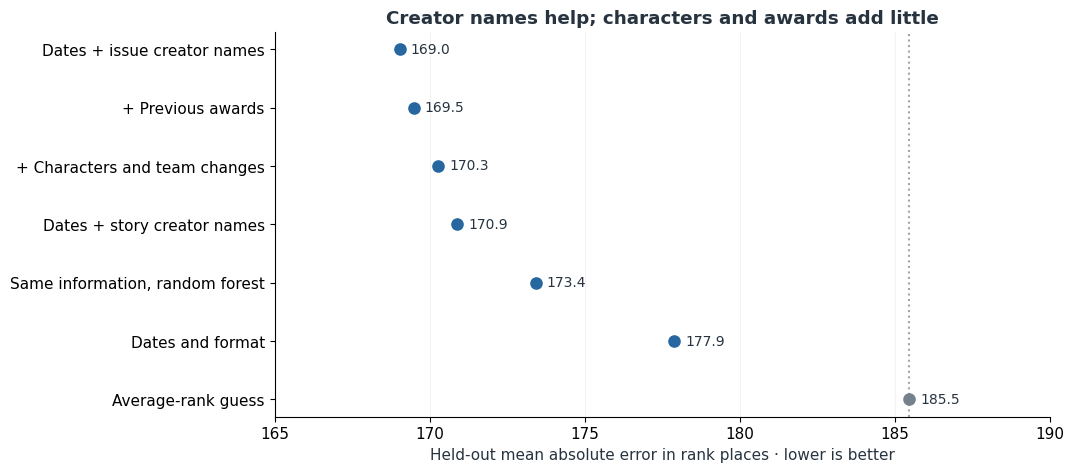

In [3]:
from sklearn.dummy import DummyRegressor
X=feature_frame(s)
y=s['rank'].to_numpy(dtype=float)
assert not {'rank','rank_percentile','source_rank','title','story_id'} & set(X)
context=BIBLIOGRAPHY+CRAFT+AWARD_CONTROLS
narrative_roles=['narrative_'+r for r in ROLES]
models={
    'Mean baseline':DummyRegressor(),
    'Era / format':regression(BIBLIOGRAPHY),
    'Whole-issue credits':regression(BIBLIOGRAPHY+AWARD_CONTROLS,ROLES),
    'Narrative credits':regression(BIBLIOGRAPHY+AWARD_CONTROLS,narrative_roles),
    'Cast + craft':regression(context,narrative_roles+CAST),
    'Cast + craft + prior awards':regression(context+AWARDS,narrative_roles+CAST),
    'Random forest: expanded':regression(context+AWARDS,narrative_roles+CAST,forest=True),
}
groups,folds=grouped_folds(s,issues)
fold_number=np.empty(N,dtype=int)
for k,(_,test) in enumerate(folds):fold_number[test]=k
pd.DataFrame({'story_id':s.story_id,'group':groups,'fold':fold_number}).to_csv(REPORT/'validation_folds.csv',index=False)
print(f'{len(set(groups))} connected groups; largest {pd.Series(groups).value_counts().max()} entries')
print('Every fold keeps both shared issues and episode companions together.')
oof,fitted,fold_metrics=fit_oof(models,X,y,folds)
summary=model_summary(y,oof)
summary=summary.drop(columns='Spearman').merge(
    fold_metrics.groupby('model')[['Spearman','Kendall_tau']].mean().reset_index(),on='model')
summary=summary.rename(columns={'Spearman':'mean_fold_Spearman','Kendall_tau':'mean_fold_Kendall'})
summary.to_csv(REPORT/'model_summary.csv',index=False)
fold_metrics.to_csv(REPORT/'cv_metrics.csv',index=False)

model_labels={'Mean baseline':'Average-rank guess','Era / format':'Dates and format',
    'Whole-issue credits':'Dates + issue creator names','Narrative credits':'Dates + story creator names',
    'Cast + craft':'+ Characters and team changes','Cast + craft + prior awards':'+ Previous awards',
    'Random forest: expanded':'Same information, random forest'}
fig,ax=plt.subplots(figsize=(10,5))
shown=summary.set_index('model').MAE_rank_places.sort_values()
for pos,(name,value) in enumerate(shown.items()):
    color=COLORS['grey'] if name=='Mean baseline' else COLORS['blue']
    ax.scatter(value,pos,color=color,s=65,zorder=3)
    ax.text(value+.35,pos,f'{value:.1f}',va='center',fontsize=10)
ax.axvline(shown['Mean baseline'],ls=':',color=COLORS['grey'],alpha=.7)
ax.set(yticks=range(len(shown)),yticklabels=[model_labels[x] for x in shown.index],xlim=(165,190),
       xlabel='Held-out mean absolute error in rank places · lower is better',
       title='Creator names help; characters and awards add little')
ax.invert_yaxis();ax.xaxis.grid(True,alpha=.15);ax.set_axisbelow(True)
save_figure(fig,REPORT,'model-benchmarks')

Publication details and the names of each issue's creators reduce the average miss from **185.5 to 169.0 places**. Adding characters, team changes, and awards barely changes that. All the models remain pretty rough predictors.

Curiously, removing people who only worked on unrelated backups doesn't improve predictions. Their names may help identify when and where the comic was published. That's a plausible explanation, not a reason to list them as its creators.

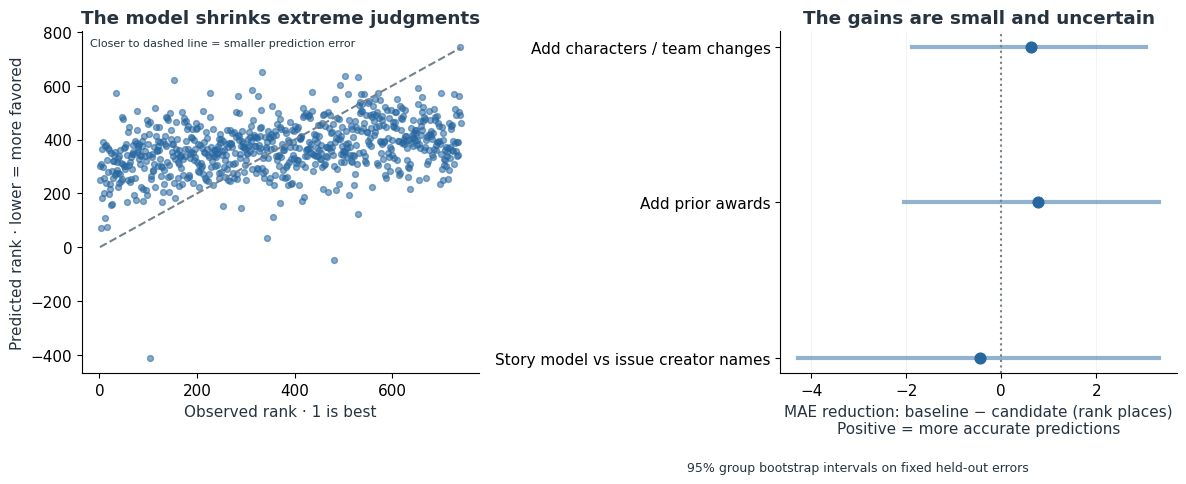

In [4]:
comparisons=[('Narrative credits','Cast + craft'),('Cast + craft','Cast + craft + prior awards'),
             ('Whole-issue credits','Cast + craft + prior awards')]
gains=pd.DataFrame([{'baseline':a,'candidate':b,**bootstrap_gain(y,oof[a],oof[b],groups)} for a,b in comparisons])

gains.to_csv(REPORT/'feature_block_gains.csv',index=False)
full='Cast + craft + prior awards'
fig,axes=plt.subplots(1,2,figsize=(12,4.6))
axes[0].scatter(y,oof[full],s=18,alpha=.55,color=COLORS['blue'])
axes[0].plot([1,N],[1,N],ls='--',color=COLORS['grey'])
axes[0].text(.02,.98,'Closer to dashed line = smaller prediction error',transform=axes[0].transAxes,va='top',fontsize=8)
axes[0].set(xlabel='Observed rank · 1 is best',ylabel='Predicted rank · lower = more favored',title='The model shrinks extreme judgments')
for pos,(_,row) in enumerate(gains.iterrows()):
    axes[1].plot([row.ci_low,row.ci_high],[pos,pos],lw=3,color=COLORS['blue'],alpha=.5)
    axes[1].scatter(row.gain_rank_places,pos,s=60,color=COLORS['blue'])
axes[1].axvline(0,ls=':',color=COLORS['grey'])
axes[1].set(yticks=range(3),yticklabels=['Add characters / team changes','Add prior awards','Story model vs issue creator names'],
            xlabel='MAE reduction: baseline − candidate (rank places)\nPositive = more accurate predictions',
            title='The gains are small and uncertain')
axes[1].invert_yaxis();axes[1].xaxis.grid(True,alpha=.15);axes[1].set_axisbelow(True)
fig.text(.72,-.04,'95% group bootstrap intervals on fixed held-out errors',ha='center',fontsize=9)
fig.tight_layout();save_figure(fig,REPORT,'model-calibration')

Character names and team details save **0.62 places** on average; prior awards save **0.78**. Both uncertainty intervals cross zero.

The scatterplot shows the bigger problem: predictions bunch toward the middle instead of following the diagonal. A model this reluctant to predict extremes will disagree with many of the hosts' strongest favorites and dislikes. Those disagreements alone aren't a reason to rerank them.

<details><summary>Uncertainty intervals</summary>

The bars are 95% bootstrap intervals, resampling saved errors by connected episode/issue group. They exclude refitting uncertainty and uncertainty from exploratory choices.

The model with characters, team details, and awards gains −0.46 places [−4.27, 3.31] over the one using all creators named in each issue. It does not reliably improve predictions.

</details>

## 3. Which information does the model rely on?

Shuffle the dates, issue counts, creator counts, and data-completeness fields, and prediction error rises by about **11 places**. Shuffle writer names and it rises by about **4**. Colorist, letterer, and editor names together account for about **3.5**.

The dates and other basic details matter most here. Creator names can partly substitute for each other: a recurring letterer may identify much the same run as its writer. Shuffling one leaves the other clue available, so this doesn't tell us whose work matters most to the comic.

<details><summary>Permutation and coefficients</summary>

Feature blocks are shuffled within each validation fold, preserving missingness patterns and eligibility. Error bars show variation across folds.

The saved Ridge coefficients are conditional associations after regularization. Negative values favor better predicted ranks; they don't measure creator ability.

</details>

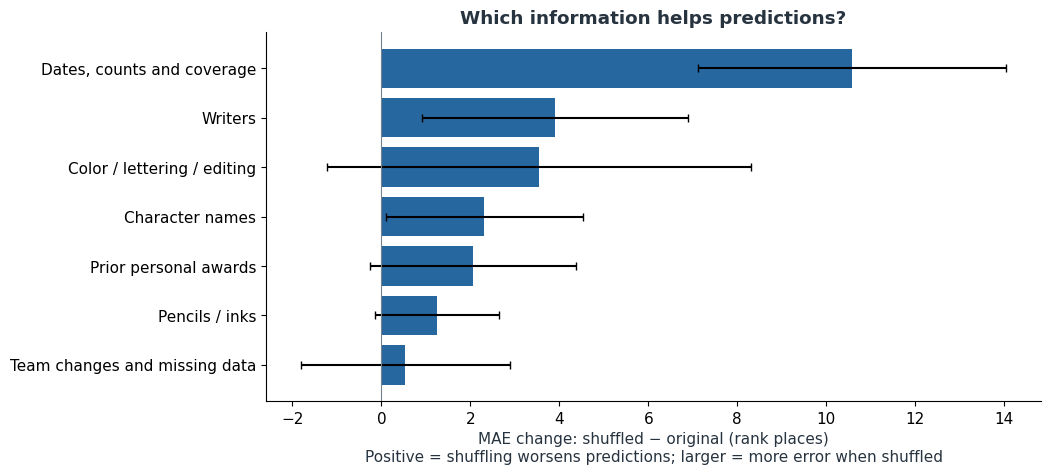

In [5]:
blocks={
    'Bibliography / scope controls':BIBLIOGRAPHY+AWARD_CONTROLS,
    'Writers':['narrative_writers'],
    'Pencils / inks':['narrative_pencilers','narrative_inkers'],
    'Color / lettering / editing':['narrative_colorists','narrative_letterers','narrative_editors'],
    'Cast identities':CAST,
    'Craft / coverage':CRAFT,
    'Prior personal awards':AWARDS,
}
importance=block_importance(fitted[full],X,y,folds,blocks,repeats=5)
importance.to_csv(REPORT/'permutation_importance.csv',index=False)
imp=importance.groupby(['fold','block']).MAE_increase_rank_places.mean().groupby('block').agg(['mean','std']).sort_values('mean')

fig,ax=plt.subplots(figsize=(10,4.8))
ax.barh([{'Bibliography / scope controls':'Dates, counts and coverage','Cast identities':'Character names','Craft / coverage':'Team changes and missing data'}.get(x,x) for x in imp.index],imp['mean'],xerr=imp['std'].fillna(0),color=COLORS['blue'],capsize=3)
ax.axvline(0,color=COLORS['grey'],lw=.8)
ax.set(xlabel='MAE change: shuffled − original (rank places)\nPositive = shuffling worsens predictions; larger = more error when shuffled',title='Which information helps predictions?')
save_figure(fig,REPORT,'model-block-importance')

coefficients=[]
for fold,model in enumerate(fitted[full]):
    coefficients.extend({'fold':fold,'feature':name,'coefficient':value} for name,value in zip(
        model[0].get_feature_names_out(),model[-1].coef_))
coef=pd.DataFrame(coefficients).groupby('feature').coefficient.agg(['mean','std','count'])
coef.to_csv(REPORT/'ridge_coefficients.csv')
creators=coef[coef.index.str.startswith(('narrative_writers__','narrative_pencilers__')) & coef['count'].ge(4)]



## 4. What happens with a new artist or a later episode?

The ordinary folds can include the same creator in training and testing. To make the task harder, we hold out the five most frequent pencilers one at a time, removing every story they worked on in **any narrative role** from training. Their connected episode and issue groups leave too.

We also train on earlier podcast discussions and test on later ones.

In [6]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error,r2_score

dates=pd.to_datetime(s.discussion_date)
cutoff=dates.sort_values().iloc[int(.8*N)]
test=np.flatnonzero(dates.ge(cutoff));train=np.flatnonzero(dates.lt(cutoff)&~pd.Series(groups).isin(groups[test]))
assert set(groups[train]).isdisjoint(groups[test])
model=clone(models[full]).fit(X.iloc[train],y[train]);prediction=model.predict(X.iloc[test])
time_result={'cutoff':str(cutoff.date()),'n_train':len(train),'n_test':len(test),
             'model_MAE':mean_absolute_error(y[test],prediction),'mean_baseline_MAE':mean_absolute_error(y[test],np.repeat(y[train].mean(),len(test))),
             'R2':r2_score(y[test],prediction)}
(REPORT/'chronological_holdout.json').write_text(json.dumps(time_result,indent=2))

artist_counts=s.narrative_pencilers.map(split_set).explode().value_counts().head(5)
heldout=[]
for artist,n in artist_counts.items():
    test_mask=s.narrative_pencilers.map(lambda names:artist in split_set(names))
    any_role=s[narrative_roles].apply(lambda row:any(artist in split_set(value) for value in row),axis=1)
    test=np.flatnonzero(test_mask)
    train=np.flatnonzero(~any_role & ~pd.Series(groups).isin(groups[test]))
    assert not any_role.iloc[train].any() and set(groups[train]).isdisjoint(groups[test])
    m=clone(models[full]).fit(X.iloc[train],y[train]);pred=m.predict(X.iloc[test])
    heldout.append({'held_out_creator':artist,'n_test':len(test),'MAE':mean_absolute_error(y[test],pred),
                    'baseline_MAE':mean_absolute_error(y[test],np.repeat(y[train].mean(),len(test)))})
heldout=pd.DataFrame(heldout)
print('MAE = average absolute miss in rank places; lower means more accurate predictions.')
display(heldout.rename(columns={'held_out_creator':'Artist held out','n_test':'Stories','MAE':'Model MAE · lower = better','baseline_MAE':'Mean-guess MAE · lower = better'}).round(1));heldout.to_csv(REPORT/'creator_holdouts.csv',index=False)

MAE = average absolute miss in rank places; lower means more accurate predictions.


,Artist held out,Stories,Model MAE · lower = better,Mean-guess MAE · lower = better
0,Jim Aparo,24,153.9,169.3
1,Bob Kane,20,125.6,190.5
2,Norm Breyfogle,19,135.2,139.5
3,Neal Adams,16,150.3,173.2
4,Kelley Jones,16,238.4,212.0


Jim Aparo's stories produce an average miss of **153.9 places**, versus **169.3** for the mean guess. Kelley Jones's produce **238.4**, versus **212.0**. The model handles some unfamiliar artists better than others, even with familiar writers and characters still available as clues.

The later-discussion test saves just **2.7 rank places** over its baseline. Neither check suggests we'd get dependable predictions for new episodes.

<details><summary>Holdout limitations</summary>

The date split predicts current ranks, using earlier discussions for training and later ones for testing. Overlapping episode/issue groups are removed from training. We don't have rankings after every episode, so this cannot measure historical rank drift.

R² is −0.028. Absolute errors are lower than in ordinary validation for both the model and baseline; comparing only model errors across those samples would overstate transfer.

Artist holdouts are chosen by frequency before inspecting their errors.

</details>

## 5. Which books surprise both models?

For *Undone*, Ridge predicts roughly **#485** and the forest **#491**, against the hosts' **#47**. Neither model knows about its silence or treatment of grief. That makes plot information an obvious next experiment.

The tables show other stories where both models disagree with the hosts in the same direction. The tables exclude unresolved issue and story matches.

<details><summary>Table ordering</summary>

`predicted_rank` is the raw regression estimate. `predicted_order` sorts the held-out predictions, and the ordering gap selects these examples. Combining predictions from five fitted models can introduce differences in prediction levels, so this ordering is diagnostic rather than a proposed replacement ranking.

</details>

In [7]:
predictions=s[['story_id','title','rank','discussion_date','substory_attribution_coverage','metadata_complete']].copy()
predictions['predicted_rank']=oof[full]
predictions['predicted_order']=pd.Series(oof[full]).rank(method='average')
predictions['forest_prediction']=oof['Random forest: expanded']
predictions['actual_minus_prediction']=predictions['rank']-predictions.predicted_rank
predictions['ordering_gap']=predictions['rank']-predictions.predicted_order
predictions['forest_predicted_order']=pd.Series(oof['Random forest: expanded']).rank(method='average')
predictions['model_agreement']=np.sign(predictions.ordering_gap)==np.sign(y-predictions.forest_predicted_order)
predictions['fold']=fold_number
predictions.to_csv(REPORT/'reranking_candidates.csv',index=False)
clean=predictions[predictions.metadata_complete & predictions.substory_attribution_coverage.eq(1) & predictions.model_agreement]
cols=['title','rank','predicted_rank','forest_prediction']
labels={'title':'Story','rank':'BatChat rank · 1 = best','predicted_rank':'Ridge rank · lower = more favored','forest_prediction':'Forest rank · lower = more favored'}
print('Hosts liked these more than their metadata suggested:')
display(clean.nsmallest(5,'ordering_gap')[cols].rename(columns=labels).round(0))
print('Hosts liked these less than their metadata suggested:')
display(clean.nlargest(5,'ordering_gap')[cols].rename(columns=labels).round(0))

watch=[]
for row in s.itertuples():
    for name in split_set(row.creator_watch_names):
        roles=[role for role in ROLES+['executive_editors'] if name in split_set(getattr(row,role))]
        narrative=[role for role in narrative_roles if name in split_set(getattr(row,role))]
        watch.append({'story_id':row.story_id,'creator':name,'whole_issue_roles':'|'.join(roles),
                      'narrative_credit_hit':bool(narrative)})
watch=pd.DataFrame(watch)

watch.to_csv(REPORT/'creator_watch_role_audit.csv',index=False)
assert len(predictions)==N and np.isfinite(predictions.predicted_rank).all()

Hosts liked these more than their metadata suggested:


,Story,BatChat rank · 1 = best,Ridge rank · lower = more favored,Forest rank · lower = more favored
32,The Dark Knight Returns: The Last Crusade,33,572.0,368.0
46,Undone,47,485.0,491.0
76,Batman: Eternal Part 1,77,504.0,355.0
47,Night of the Stalker,48,476.0,463.0
113,The Joker/ The Joker Returns,114,518.0,519.0


Hosts liked these less than their metadata suggested:


,Story,BatChat rank · 1 = best,Ridge rank · lower = more favored,Forest rank · lower = more favored
696,Knightquest: The Search,697,234.0,278.0
714,Batman/Houdini: The Devil’s Workshop,715,253.0,280.0
702,The Wedding,703,252.0,363.0
635,Demons,636,215.0,198.0
654,Batman: Harley & Ivy #1-3,655,250.0,276.0


*The Last Crusade* is another unexpected favorite, though the models disagree much more about its rank. *Undone* is the clearer shared miss. Let's see whether plots help across the whole list.

<details><summary>Creator-event audit</summary>

The saved audit distinguishes ranked-story credits from unrelated backups and executive credits. Its small, historically entangled event list cannot establish misconduct-related ranking bias or support a before-and-after comparison.

</details>

## 6. Does knowing the plot help?

We represent the summaries with **TF-IDF**, a weighted bag of words. Words gain weight when repeated within a summary and lose weight when common across summaries. That can pick up names and subjects, but not the sequence of a scene.

Summary availability and length already tell us something about publication era. To separate that from the words themselves, the control model gets creator names and the other metadata, plus text availability, length, and completeness. Then we add the words.

<details><summary>Text coverage, cleaning, and validation</summary>

The corpus has 1,711 available synopsis fields containing 703,219 words. Text covers 587 stories; 481 have every selected summary and a complete issue list. All 740 stories stay in the model comparison. Subset scores evaluate those same held-out predictions.

The audit removed a critical-reception section from Arkham Asylum and credit boilerplate from two anthology summaries. Plot prose remains uncapped. Each story becomes an unordered bag of its available summaries, with duplicate text counted once.

Shared source narratives and identical normalized text join the episode/issue validation groups, leaving 231 groups in this snapshot. Vocabulary and IDF are fitted inside training splits. Each outer fold tunes Ridge's penalty over 1, 10, and 100 using three inner grouped folds. Vectorizer settings are fixed.

These models are tuned separately from the earlier fixed-penalty benchmark. The earlier 169-place result is not this experiment's control.

</details>

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV,GroupKFold
from sklearn.pipeline import make_pipeline
from scripts.analysis import plot_documents

texts=pd.read_csv(ROOT/'data/processed/story_texts.csv')
documents=plot_documents(s,texts)
X=feature_frame(s).join(documents.drop(columns='story_id'))
y=s['rank'].to_numpy(dtype=float)
text_groups,text_folds=grouped_folds(s,issues,texts=texts)
plot_controls=['plot_available','plot_complete','plot_fraction','log_plot_words','log_plot_units']
numeric=BIBLIOGRAPHY+CRAFT+AWARDS+AWARD_CONTROLS
roles=['narrative_'+r for r in ROLES]+CAST
# The vocabulary and inverse-document frequencies are learned inside each training split.
def bag_of_words():
    return TfidfVectorizer(stop_words='english',min_df=3,max_df=.95,max_features=12000,
                          ngram_range=(1,1),sublinear_tf=True,strip_accents='unicode')
control=regression(numeric+plot_controls,roles)
with_words=clone(control)
with_words[0].transformers.append(('plot',bag_of_words(),'plot_text'))
words_only=make_pipeline(ColumnTransformer([('plot',bag_of_words(),'plot_text')]),Ridge(solver='lsqr'))
text_models={'Mean guess':DummyRegressor(), 'Plot words only':words_only,
             'Credits + text coverage':control,'Credits + text coverage + words':with_words}
text_predictions={name:np.empty(len(s)) for name in text_models}
text_fitted={name:[] for name in text_models}
choices=[]
for fold,(train,test) in enumerate(text_folds):
    inner=list(GroupKFold(n_splits=3).split(X.iloc[train],groups=text_groups[train]))
    for name,template in text_models.items():
        if name=='Mean guess':
            model=clone(template).fit(X.iloc[train],y[train]);alpha=None
        else:
            search=GridSearchCV(template,{'ridge__alpha':[1.,10.,100.]},cv=inner,
                                scoring='neg_mean_absolute_error',n_jobs=1,error_score='raise')
            search.fit(X.iloc[train],y[train]);model=search.best_estimator_;alpha=search.best_params_['ridge__alpha']
        text_predictions[name][test]=model.predict(X.iloc[test]);text_fitted[name].append(model)
        choices.append({'fold':fold,'model':name,'alpha':alpha,'test_size':len(test)})
assert all(np.isfinite(p).all() for p in text_predictions.values())
cohorts={'All stories':np.ones(len(s),dtype=bool),'Some plot text':documents.plot_available.eq(1).to_numpy(),
         'All selected plots present':documents.plot_complete.eq(1).to_numpy()}
text_scores=[];text_gains=[]
for label,mask in cohorts.items():
    for name,prediction in text_predictions.items():
        text_scores.append({'cohort':label,'n':int(mask.sum()),'model':name,
                            'MAE_rank_places':mean_absolute_error(y[mask],prediction[mask])})
    text_gains.append({'cohort':label,'n':int(mask.sum()),**bootstrap_gain(y[mask],
        text_predictions['Credits + text coverage'][mask],text_predictions['Credits + text coverage + words'][mask],text_groups[mask])})
text_scores=pd.DataFrame(text_scores);text_gains=pd.DataFrame(text_gains)
text_scores.to_csv(REPORT/'plot_model_scores.csv',index=False)
text_gains.to_csv(REPORT/'plot_model_gains.csv',index=False)
pd.DataFrame(choices).to_csv(REPORT/'plot_model_tuning.csv',index=False)
pd.DataFrame({'story_id':s.story_id,'rank':y,'group':text_groups,**text_predictions}).to_csv(REPORT/'plot_model_predictions.csv',index=False)
display(text_scores.assign(model=text_scores.model.replace({'Credits + text coverage':'Names, dates, characters, awards + text coverage','Credits + text coverage + words':'Same information + plot words'}))[text_scores.cohort.eq('All stories')][['model','MAE_rank_places']].rename(columns={'model':'Information given to the model','MAE_rank_places':'MAE in rank places · lower = better'}).round(1))

# Keep word coefficients available for inspection; they are associations in wiki summaries.
word_coefficients=[]
for fold,model in enumerate(text_fitted['Plot words only']):
    word_coefficients.extend({'fold':fold,'term':name.removeprefix('plot__'),'coefficient':value}
        for name,value in zip(model[0].get_feature_names_out(),model[-1].coef_))
word_coefficients=pd.DataFrame(word_coefficients)
word_coefficients.to_csv(REPORT/'plot_word_coefficients.csv',index=False)


,Information given to the model,MAE in rank places · lower = better
0,Mean guess,185.5
1,Plot words only,179.2
2,"Names, dates, characters, awards + text coverage",170.9
3,Same information + plot words,170.6


Words alone miss by about **179 places**, beating the mean guess of **185.5**. Once the model has creator names, publication details, and text coverage, adding words barely helps: error falls from **170.88 to 170.57**, a gain of **0.31 places** with an interval that includes zero.

Restricting evaluation to complete summaries leaves a similarly small gain. Among stories with some text, the interval barely clears zero, but the gain is still only **0.40 places** against an error near 170. None of these comparisons saves even one place on average.

The bars below resample saved held-out errors, without refitting the models.

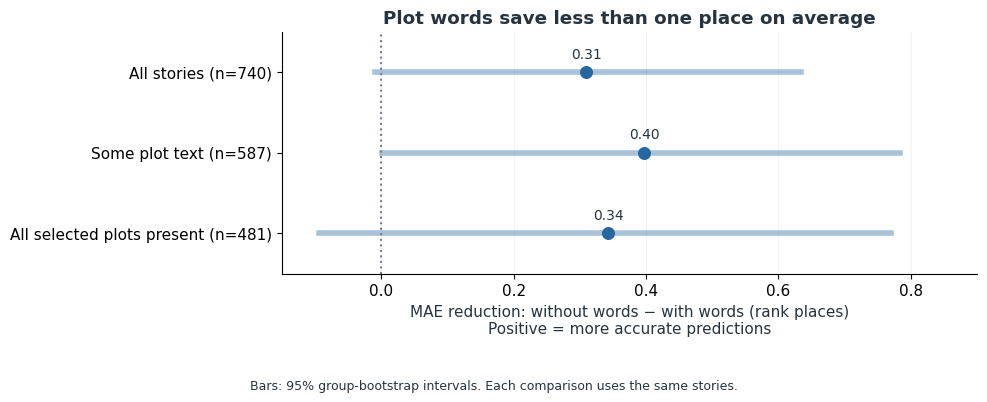

In [9]:
fig,ax=plt.subplots(figsize=(10,4))
for pos,(_,row) in enumerate(text_gains.iterrows()):
    ax.plot([row.ci_low,row.ci_high],[pos,pos],color=COLORS['blue'],lw=4,alpha=.4)
    ax.scatter(row.gain_rank_places,pos,color=COLORS['blue'],s=70,zorder=3)
    ax.annotate(f'{row.gain_rank_places:.2f}',(row.gain_rank_places,pos),xytext=(0,10),
                textcoords='offset points',ha='center',fontsize=10)
ax.axvline(0,color=COLORS['grey'],ls=':')
ax.set(yticks=range(len(text_gains)),
       yticklabels=[f'{r.cohort} (n={r.n})' for r in text_gains.itertuples()],
       xlabel='MAE reduction: without words − with words (rank places)\nPositive = more accurate predictions',
       title='Plot words save less than one place on average',xlim=(-.15,.9),ylim=(2.5,-.5))
ax.xaxis.grid(True,alpha=.15);ax.set_axisbelow(True)
fig.text(.5,.01,'Bars: 95% group-bootstrap intervals. Each comparison uses the same stories.',ha='center',fontsize=9)
fig.tight_layout(rect=(0,.1,1,1));save_figure(fig,REPORT,'model-plot-gain')

## 7. Similar words, very different reading experiences

The words are more promising as a browsing tool. For *Undone*, *Ego*, and *The Clown at Midnight*, we find the closest synopsis outside the same issue/episode group, requiring complete summaries on both sides.

These examples come from the storytelling comparisons in [Notebook 2](2.0-batchat-the-art-of-gotham.ipynb); the algorithm picks their neighbors. The annotations show which shared words contribute most. This uses the available corpus for browsing, rather than testing another predictor.

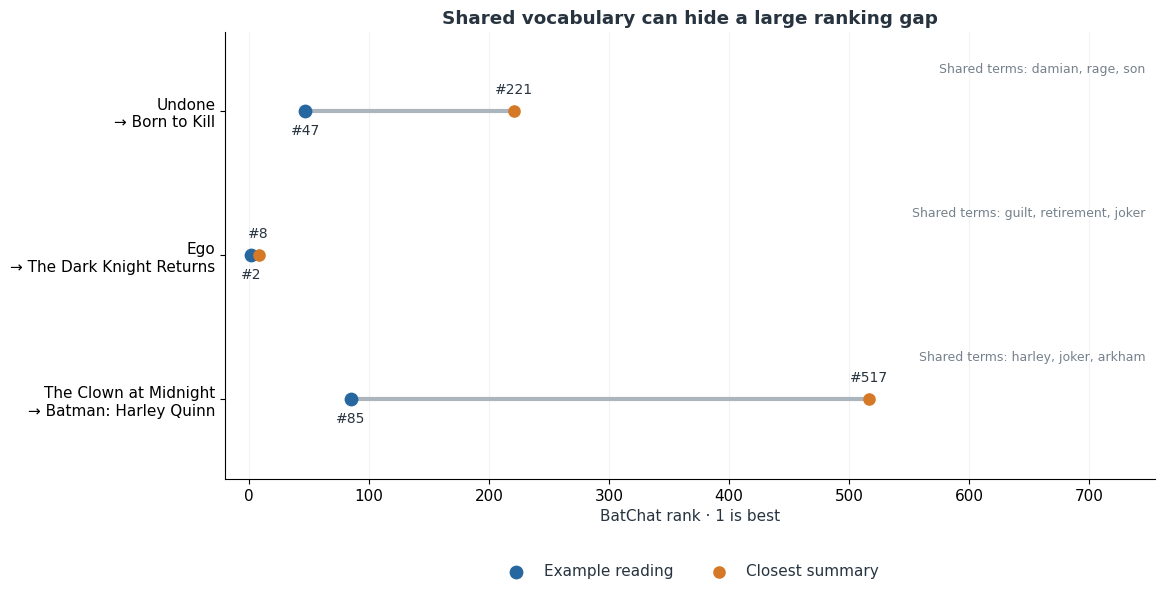

In [10]:
from sklearn.metrics.pairwise import cosine_similarity
available=np.flatnonzero(documents.plot_complete.eq(1))
retrieval=TfidfVectorizer(stop_words='english',min_df=3,max_df=.95,max_features=12000,ngram_range=(1,1),sublinear_tf=True,strip_accents='unicode')
vectors=retrieval.fit_transform(documents.plot_text.iloc[available]);similarity=cosine_similarity(vectors)
lookup={idx:pos for pos,idx in enumerate(available)};records=[]
for title in ['Undone','Ego','The Clown at Midnight']:
 idx=s.index[s.title.eq(title)][0];assert idx in lookup
 pos=lookup[idx];scores=similarity[pos].copy();scores[text_groups[available]==text_groups[idx]]=-1
 match=int(scores.argmax());other=available[match]
 overlap=vectors[pos].multiply(vectors[match]).toarray().ravel()
 terms=retrieval.get_feature_names_out()[np.argsort(-overlap)[:3]]
 records.append({'anchor':title,'anchor_rank':int(s['rank'].iloc[idx]),'neighbor':s.title.iloc[other],
 'neighbor_rank':int(s['rank'].iloc[other]),'cosine_similarity':float(scores[match]),'shared_terms':', '.join(terms),
 'anchor_id':s.story_id.iloc[idx],'neighbor_id':s.story_id.iloc[other]})
neighbors=pd.DataFrame(records);neighbors.to_csv(REPORT/'plot_neighbors.csv',index=False)


from textwrap import fill
fig,ax=plt.subplots(figsize=(12,5.8))
for pos,row in enumerate(neighbors.itertuples()):
    ax.plot([row.anchor_rank,row.neighbor_rank],[pos,pos],color='#ABB5BD',lw=3,zorder=1)
    ax.scatter(row.anchor_rank,pos,color=COLORS['blue'],s=80,zorder=3,label='Example reading' if pos==0 else None)
    ax.scatter(row.neighbor_rank,pos,color=COLORS['orange'],s=65,zorder=3,label='Closest summary' if pos==0 else None)
    for rank,offset in [(row.anchor_rank,-17),(row.neighbor_rank,13)]:
        ax.annotate(f'#{rank}',(rank,pos),xytext=(0,offset),textcoords='offset points',ha='center',fontsize=10)
    ax.text(.99,pos-.27,'Shared terms: '+row.shared_terms,transform=ax.get_yaxis_transform(),
            ha='right',fontsize=9,color=COLORS['grey'])
ax.set(yticks=range(len(neighbors)),
       yticklabels=[fill(r.anchor,27)+'\n→ '+fill(r.neighbor,27) for r in neighbors.itertuples()],
       xlabel='BatChat rank · 1 is best',title='Shared vocabulary can hide a large ranking gap',
       xlim=(-20,N+15),ylim=(-.55,len(neighbors)-.45))
ax.invert_yaxis();ax.xaxis.grid(True,alpha=.15);ax.set_axisbelow(True)
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.16),ncol=2,frameon=False)
save_figure(fig,REPORT,'model-plot-neighbors')


*Undone* finds *Born to Kill* through **Damian, rage, and son**: **#47 versus #221**. *The Clown at Midnight* finds *Batman: Harley Quinn* through **Harley, Joker, and Arkham**: **#85 versus #517**. Meanwhile, **guilt, retirement, and Joker** connect *Ego* with *The Dark Knight Returns*, two favorites at **#2 and #8**.

Knowing who made the comic and when it appeared helps predict a little of the hosts' taste; these plot features add very little. That's a result about these models and summaries, not proof that plot doesn't matter. A synopsis can describe both a silent sequence and an illustrated prose passage in similar language while losing their formal differences.

I'd take those pairs back to the pages. Count panels and words, mark silent sequences, and record edition-specific changes. Those features could test whether the way a comic tells its story explains something that the creators' names and publication dates don't explain.

[Notebook 2](2.0-batchat-the-art-of-gotham.ipynb) examines the creative teams and storytelling examples. [Notebook 3](3.0-batchat-versus-the-crowd.ipynb) checks the audience disagreements.

**Reuse the work:** [Kaggle setup](../references/kaggle-sharing.md) · [Data dictionary](../references/data_dictionary.md). Scores, predictions, and word-based neighbors are saved in `reports/`.